# Function 5: Week 5 prediction and kernel diagnostics

Assess the week-5 result against its saved pre-evaluation prediction, then compare the same five kernel specifications with shared shuffled folds and leakage-free historical backtests through week 5. This is read-only; it does not change observations, predictions, or the optimization policy. The week-5 result is included in the aggregate observation history.

In [1]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold

from bayesian_bbo import CONFIG
from bayesian_bbo.history import load_weekly_history
from bayesian_bbo.kernels import make_comparison_kernels
from bayesian_bbo.validation import evaluate_kernel_splits

CURRENT_WEEK = 5
WEEKS = tuple(range(1, CURRENT_WEEK + 1))
FUNCTION_ID = 5
N_SPLITS = 5
RANDOM_STATE = CONFIG['random_state']
N_RESTARTS = CONFIG['n_restarts_optimizer']

data_candidates = [Path('../../data'), Path('data'), Path('../data')]
matches = [path.resolve() for path in data_candidates if (path / 'function_1').is_dir()]
if not matches:
    raise FileNotFoundError('Could not find the data directory from the notebook working directory.')
data_root = matches[0]
history = load_weekly_history(data_root, current_week=CURRENT_WEEK, function_ids=(FUNCTION_ID,))
observations = history.observations[FUNCTION_ID]
historical_results = history.records.loc[history.records.week.isin(WEEKS)].copy()
kernels = make_comparison_kernels(observations.dimension, CONFIG['length_caps'][FUNCTION_ID])
kernel_names = list(kernels) + ['Training mean']
print(f'Function {FUNCTION_ID}: {len(observations.outputs)} observations, {observations.dimension} dimensions')
print(f'Cutoff week {CURRENT_WEEK}; {N_SPLITS} folds; {N_RESTARTS} GP optimizer restarts')
display(historical_results[['week', 'observed_output', 'expected_mean', 'expected_std', 'residual']])

Function 5: 25 observations, 4 dimensions
Cutoff week 5; 5 folds; 10 GP optimizer restarts


,week,observed_output,expected_mean,expected_std,residual
0,1,1397.545109,689.501455,200.322259,3.534523
1,2,1588.598502,1720.386794,71.126598,-1.852869
2,3,3949.359248,1608.846266,24.701896,94.750337
3,4,2060.381950,4093.302693,167.549994,-12.133219
4,5,7156.856542,5312.777889,654.553522,2.817308


## 1. Week 5 result against its saved prediction

The original mean and standard deviation were recorded before evaluation, using observations only through week 4. The residual is standardized by that saved standard deviation; it tests this one outcome, not general calibration.

In [2]:
week5_record = historical_results.loc[historical_results.week == CURRENT_WEEK].iloc[0]
week5_result = pd.DataFrame([{
    'input': week5_record.candidate,
    'previous_best': week5_record.previous_best,
    'actual': week5_record.observed_output,
    'saved_mean': week5_record.expected_mean,
    'saved_std': week5_record.expected_std,
    'saved_residual_z': week5_record.residual,
    'saved_expected_best': week5_record.expected_best,
    'observed_best': week5_record.observed_best,
    'improved_incumbent': week5_record.observed_best > week5_record.previous_best,
}])
display(week5_result.T.rename(columns={0: 'Function 5, week 5'}))

,"Function 5, week 5"
input,"(0.971643, 0.960706, 0.984862, 0.99763)"
previous_best,3949.359248
actual,7156.856542
saved_mean,5312.777889
saved_std,654.553522
saved_residual_z,2.817308
saved_expected_best,5317.215045
observed_best,7156.856542
improved_incumbent,True


## 2. Shared-fold accuracy and uncertainty

Every kernel and the training-mean baseline use the same shuffled folds. Metrics pool held-out predictions. Coverage should be read alongside interval width; this reconstruction test is descriptive and is not the sequential evaluation used in section 4.

In [3]:
folds = dict(enumerate(KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE).split(observations.inputs), start=1))
oof = evaluate_kernel_splits(
    observations, kernels, folds, random_state=RANDOM_STATE,
    n_restarts_optimizer=N_RESTARTS, normalize_y=CONFIG['normalize_y'],
)
for name, rows in oof.groupby('kernel'):
    assert rows.row_index.nunique() == len(observations.outputs)
    assert len(rows) == len(observations.outputs)

def summarize_predictions(frame, groups):
    summary = frame.groupby(groups).agg(
        count=('actual', 'size'), MSE=('squared_error', 'mean'),
        MAE=('absolute_error', 'mean'), NLL=('nlpd', 'mean'),
        coverage_90=('covered_90', 'mean'), coverage_95=('covered_95', 'mean'),
        width_90=('width_90', 'mean'), width_95=('width_95', 'mean'),
        worst_abs_z=('z', lambda values: values.abs().max()),
    )
    summary['RMSE'] = np.sqrt(summary.pop('MSE'))
    return summary

oof_summary = summarize_predictions(oof, 'kernel')
oof_summary['RMSE_vs_baseline'] = oof_summary.RMSE / oof_summary.loc['Training mean', 'RMSE']
display(oof_summary.sort_values('RMSE').round(3))
print('Pooled held-out observations; results are not an unweighted mean of fold RMSEs.')

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
 

,count,MAE,NLL,coverage_90,coverage_95,width_90,width_95,worst_abs_z,RMSE,RMSE_vs_baseline
kernel,,,,,,,,,,
Rational Quadratic,25,333.484,7.409,0.92,0.96,1151.925,1372.506,3.790,607.551,0.363
Matérn 5/2,25,634.727,51.495,0.60,0.68,910.047,1084.312,31.337,1021.879,0.611
RBF,25,768.857,106.290,0.40,0.44,741.051,882.955,54.099,1118.351,0.669
Matérn 3/2,25,741.557,149.371,0.60,0.60,1039.634,1238.713,72.777,1138.808,0.681
Exp-Sine-Squared,25,898.328,8.821,0.92,0.92,4812.503,5734.046,5.114,1227.807,0.734
Training mean,25,1078.789,9.478,0.92,0.92,5068.947,6039.597,7.162,1671.642,1.000


Pooled held-out observations; results are not an unweighted mean of fold RMSEs.


## 3. Leakage-free historical backtest

For week $w$, each model is fitted only on observations with week less than $w$ and predicts the evaluated input from week $w$. These alternative kernels do not reproduce the original optimizer; compare their predictions with the separately saved historical mean. Five outcomes are still too few to establish robust coverage or select a future kernel.

In [5]:
historical_splits = {
    week: (np.flatnonzero(observations.weeks < week), np.flatnonzero(observations.weeks == week))
    for week in WEEKS
}
backtest = evaluate_kernel_splits(
    observations, kernels, historical_splits, random_state=RANDOM_STATE,
    n_restarts_optimizer=N_RESTARTS, normalize_y=CONFIG['normalize_y'],
)
assert (backtest.training_max_week < backtest.week).all()
assert (backtest['split'] == backtest.week).all()
backtest_summary = summarize_predictions(backtest, 'kernel')
display(backtest_summary.sort_values('NLL').round(3))
display(backtest[['kernel', 'week', 'training_count', 'actual', 'mean', 'std', 'lower_95', 'upper_95', 'z', 'nlpd', 'covered_95']].round(3))

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better val

,count,MAE,NLL,coverage_90,coverage_95,width_90,width_95,worst_abs_z,RMSE
kernel,,,,,,,,,
Rational Quadratic,5,996.070,22.717,0.4,0.4,1089.895,1298.599,11.877,1343.408
Exp-Sine-Squared,5,2916.612,23.422,0.0,0.2,1868.782,2226.634,8.132,3575.466
Training mean,5,2916.725,23.481,0.0,0.2,1867.220,2224.772,8.130,3575.354
RBF,5,2045.741,318.413,0.0,0.0,572.727,682.398,53.086,2544.909
Matérn 5/2,5,1554.434,758.189,0.2,0.2,751.011,894.822,85.805,1989.726
Matérn 3/2,5,1625.653,920.428,0.2,0.4,769.011,916.269,94.750,2103.050


,kernel,week,training_count,actual,mean,std,lower_95,upper_95,z,nlpd,covered_95
0,Training mean,1,20,1397.545,151.272,245.576,-330.057,632.601,5.075,19.300,False
1,Matérn 3/2,1,20,1397.545,1306.889,74.693,1160.492,1453.287,1.214,5.969,True
2,Matérn 5/2,1,20,1397.545,1347.084,64.327,1221.003,1473.165,0.784,5.391,True
3,RBF,1,20,1397.545,402.701,175.960,57.819,747.583,5.654,22.072,False
4,Rational Quadratic,1,20,1397.545,1111.536,85.783,943.401,1279.670,3.334,10.929,False
5,Exp-Sine-Squared,1,20,1397.545,151.272,248.840,-336.455,638.999,5.008,18.977,False
6,Training mean,2,21,1588.599,210.618,357.597,-490.272,911.508,3.853,14.223,False
7,Matérn 3/2,2,21,1588.599,1720.387,71.127,1580.979,1859.795,-1.853,6.900,True
8,Matérn 5/2,2,21,1588.599,1741.294,46.968,1649.237,1833.351,-3.251,10.053,False
9,RBF,2,21,1588.599,1772.143,31.831,1709.754,1834.532,-5.766,21.004,False


## 4. Week-by-week comparison

The interval plot shows the alternative kernel backtests and the originally saved mean. The week-5 marker is the primary new assessment; earlier points provide context but do not make these five outcomes independent replicates.

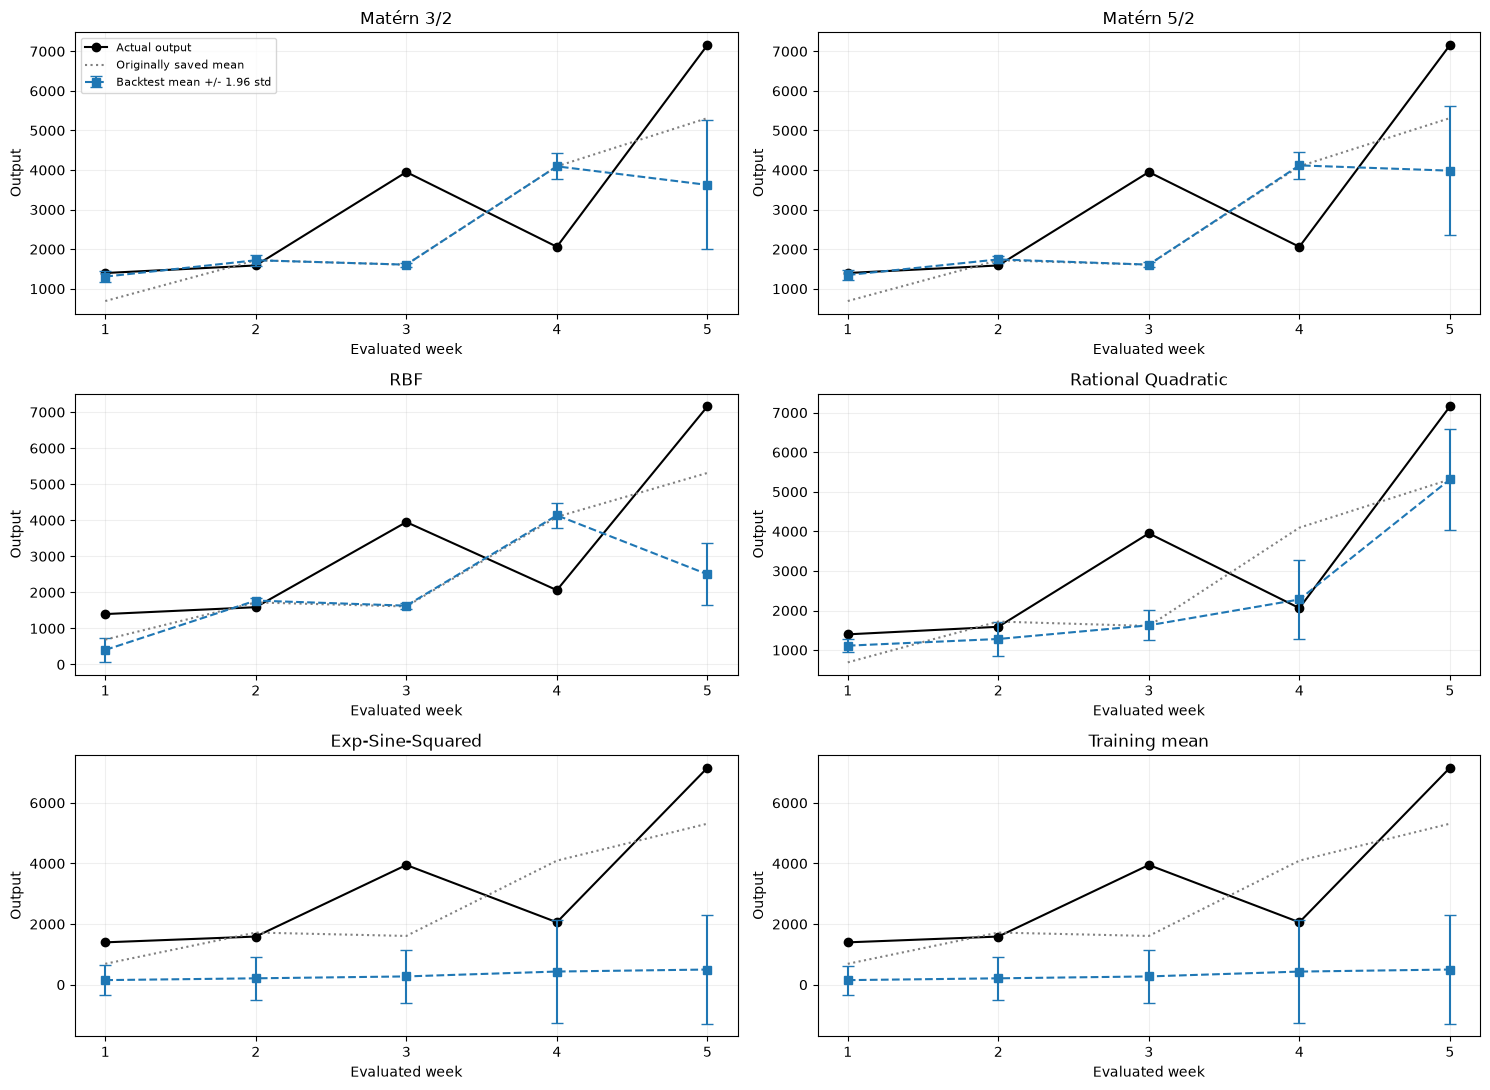

,kernel,actual,mean,std,z,nlpd,covered_95
28,Rational Quadratic,7156.8565,5312.7779,654.5535,2.8173,11.3715,False
26,Matérn 5/2,7156.8565,3984.3965,827.6282,3.8332,14.9842,False
25,Matérn 3/2,7156.8565,3624.4710,830.6388,4.2526,16.6835,False
24,Training mean,7156.8565,500.8884,912.0002,7.2982,34.3665,False
29,Exp-Sine-Squared,7156.8565,500.3106,911.8329,7.3002,34.3807,False
27,RBF,7156.8565,2501.5037,437.5384,10.6399,63.6036,False


In [6]:
fig, axes = plt.subplots(3, 2, figsize=(15, 11), squeeze=False)
for name, ax in zip(kernel_names, axes.ravel()):
    rows = backtest.loc[backtest.kernel == name].sort_values('week')
    ax.plot(rows.week, rows.actual, 'k-o', label='Actual output')
    ax.errorbar(rows.week, rows['mean'], yerr=1.96 * rows['std'], fmt='s--', capsize=4, label='Backtest mean +/- 1.96 std')
    ax.plot(historical_results.week, historical_results.expected_mean, ':', color='gray', label='Originally saved mean')
    ax.set(title=name, xlabel='Evaluated week', ylabel='Output', xticks=list(WEEKS))
    ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
display(fig)
week5_backtest = backtest.loc[backtest.week == CURRENT_WEEK, ['kernel', 'actual', 'mean', 'std', 'z', 'nlpd', 'covered_95']]
display(week5_backtest.sort_values('nlpd').round(4))
plt.close(fig)

## Interpretation limits

Lower RMSE, MAE, and NLL are better on this function and output scale. Read them with interval widths, high-output misses, and convergence warnings. Neither shuffled CV nor five sequential observations justifies automatic kernel selection or a claim about future optimization success.